Saving history.csv to history (1).csv
Saving Student_WRN34_325_KD_SLA_val45k_seed41.zip to Student_WRN34_325_KD_SLA_val45k_seed41.zip


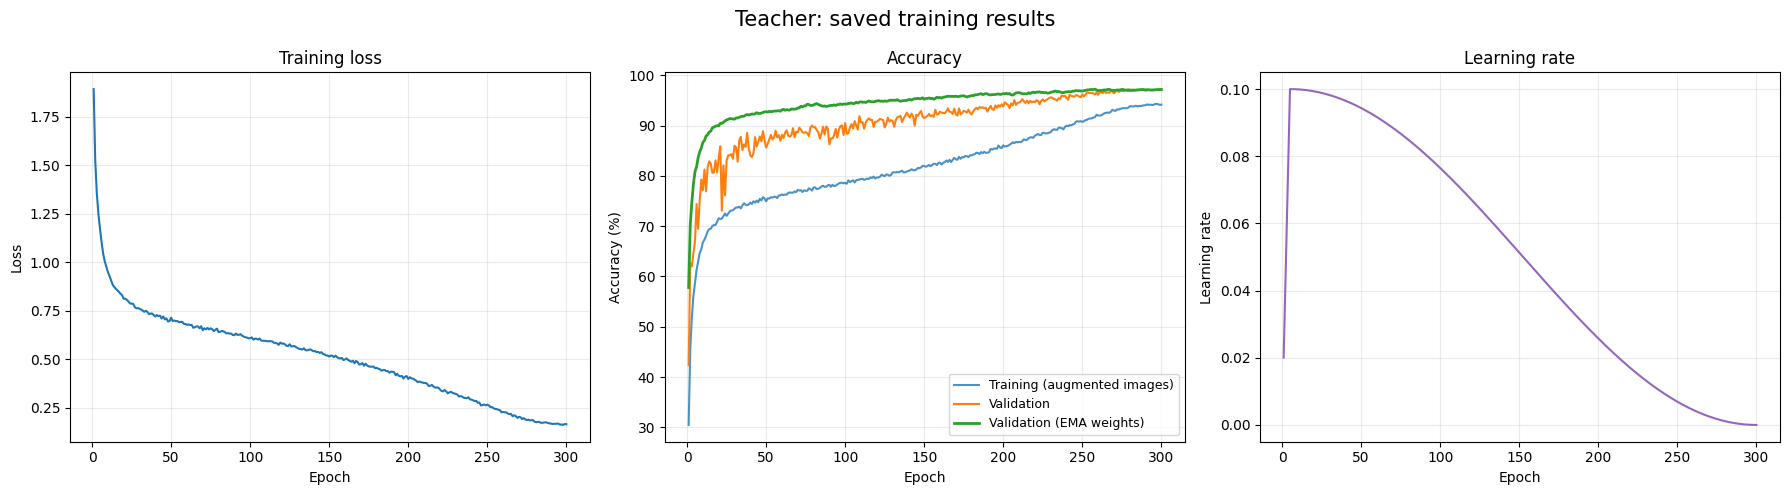

Teacher: 300 recorded epochs
Best recorded EMA validation accuracy: 97.24% at epoch 258
Graph saved: /content/training_graphs/teacher_training_curves.png



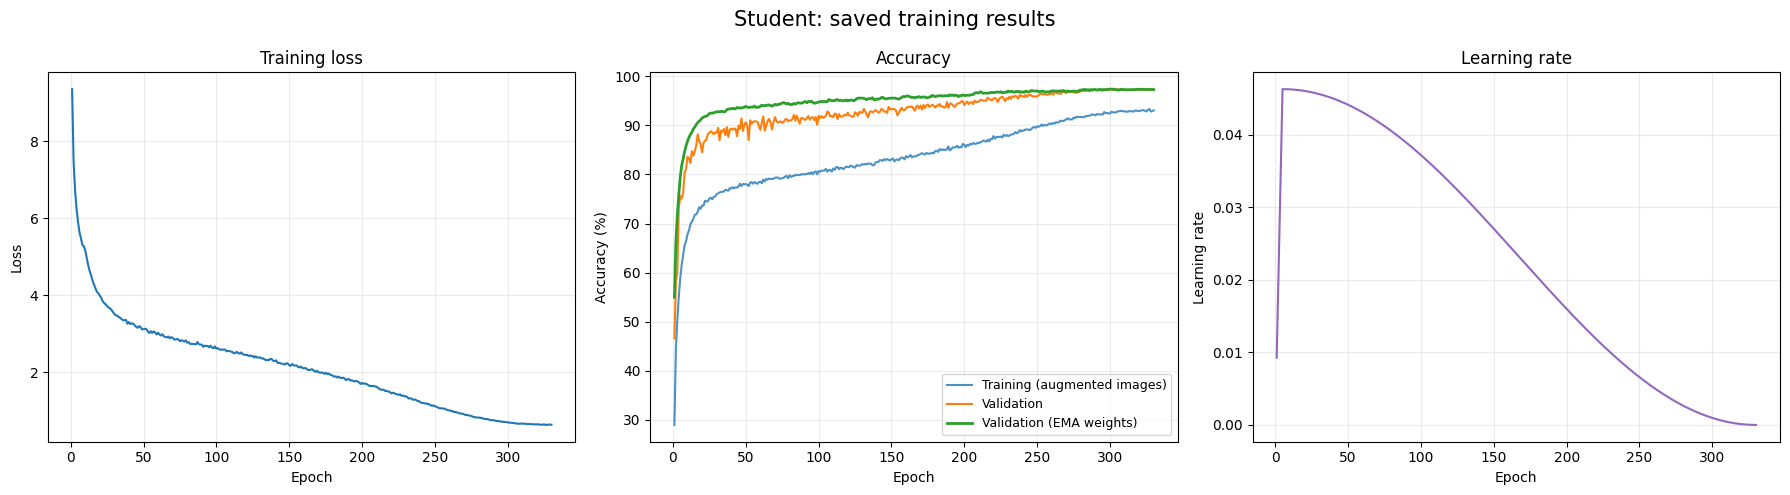

Student: 330 recorded epochs
Best recorded EMA validation accuracy: 97.38% at epoch 300
Graph saved: /content/training_graphs/student_training_curves.png



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [1]:
# We read the saved training results and draw graphs.
# This code does not train either model.

from google.colab import files
import io
import zipfile
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

uploaded = files.upload()

OUTPUT = Path("/content/training_graphs")
OUTPUT.mkdir(parents=True, exist_ok=True)

# Read the teacher history.
teacher_name = next(
    (name for name in uploaded if name.lower().endswith(".csv")),
    None
)
if teacher_name is None:
    raise ValueError("Please upload the teacher history.csv file.")

teacher_history = pd.read_csv(io.BytesIO(uploaded[teacher_name]))

# Read the student history directly from the ZIP.
student_zip = next(
    (name for name in uploaded if name.lower().endswith(".zip")),
    None
)
if student_zip is None:
    raise ValueError("Please upload the student ZIP file.")

with zipfile.ZipFile(io.BytesIO(uploaded[student_zip])) as archive:
    histories = [
        name for name in archive.namelist()
        if name.endswith("/history.csv")
        and not name.startswith("__MACOSX/")
    ]

    if len(histories) != 1:
        raise ValueError(
            f"Expected one student history.csv in the ZIP; found {histories}"
        )

    student_history = pd.read_csv(
        io.BytesIO(archive.read(histories[0]))
    )

# Draw the same set of graphs for each model.
def plot_history(history, model_name):
    required = {
        "epoch", "loss", "train_aug_acc",
        "val_acc", "val_ema", "lr"
    }
    missing = required - set(history.columns)
    if missing:
        raise ValueError(f"{model_name}: missing columns {missing}")

    history = history.sort_values("epoch")
    epochs = history["epoch"]

    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    axes[0].plot(epochs, history["loss"], color="tab:blue")
    axes[0].set_title("Training loss")
    axes[0].set_ylabel("Loss")

    axes[1].plot(
        epochs, history["train_aug_acc"],
        label="Training (augmented images)", alpha=0.8
    )
    axes[1].plot(
        epochs, history["val_acc"],
        label="Validation"
    )
    axes[1].plot(
        epochs, history["val_ema"],
        label="Validation (EMA weights)", linewidth=2
    )
    axes[1].set_title("Accuracy")
    axes[1].set_ylabel("Accuracy (%)")
    axes[1].legend(fontsize=9)

    axes[2].plot(epochs, history["lr"], color="tab:purple")
    axes[2].set_title("Learning rate")
    axes[2].set_ylabel("Learning rate")

    for ax in axes:
        ax.set_xlabel("Epoch")
        ax.grid(alpha=0.25)

    fig.suptitle(f"{model_name}: saved training results", fontsize=15)
    fig.tight_layout()

    filename = OUTPUT / f"{model_name.lower()}_training_curves.png"
    fig.savefig(filename, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    best_row = history.loc[history["val_ema"].idxmax()]
    print(f"{model_name}: {len(history)} recorded epochs")
    print(
        f"Best recorded EMA validation accuracy: "
        f"{best_row['val_ema']:.2f}% "
        f"at epoch {int(best_row['epoch'])}"
    )
    print(f"Graph saved: {filename}\n")


plot_history(teacher_history, "Teacher")
plot_history(student_history, "Student")

# Package both images for download.
graph_zip = Path("/content/training_graphs.zip")
with zipfile.ZipFile(graph_zip, "w", zipfile.ZIP_DEFLATED) as archive:
    for image in OUTPUT.glob("*.png"):
        archive.write(image, arcname=image.name)

files.download(str(graph_zip))

,Weights,TTA,Validation accuracy (%),CSV
0,tail_avg,flip,97.72,submission_tail_avg_flip.csv
1,final_ema,multi,97.70,submission_final_ema_multi.csv
2,tail_avg,cardinal,97.68,submission_tail_avg_cardinal.csv
3,final_ema,cardinal,97.68,submission_final_ema_cardinal.csv
4,tail_avg,multi,97.60,submission_tail_avg_multi.csv
5,final_ema,flip,97.54,submission_final_ema_flip.csv


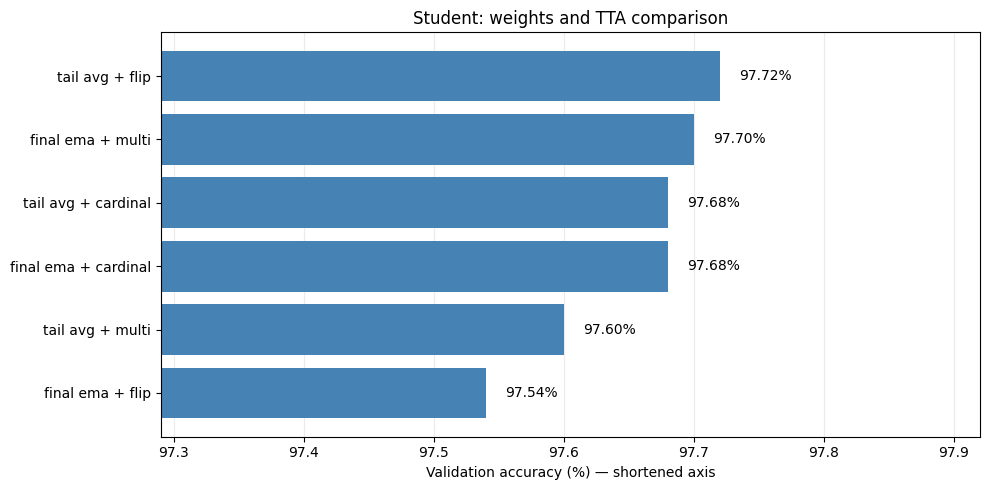

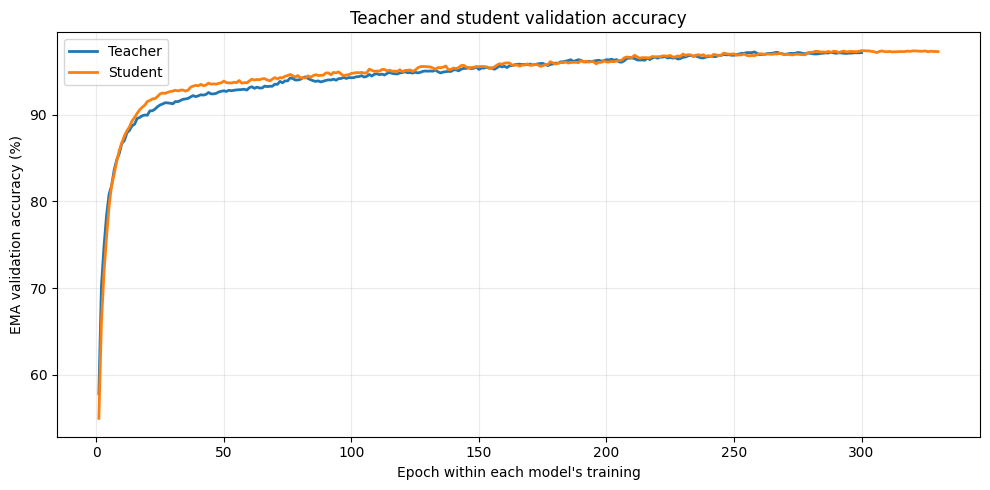

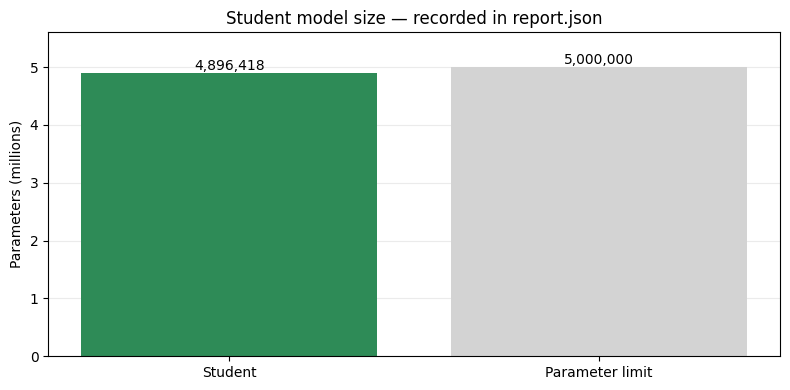

Recorded student parameters: 4,896,418
Below the limit by: 103,582 parameters


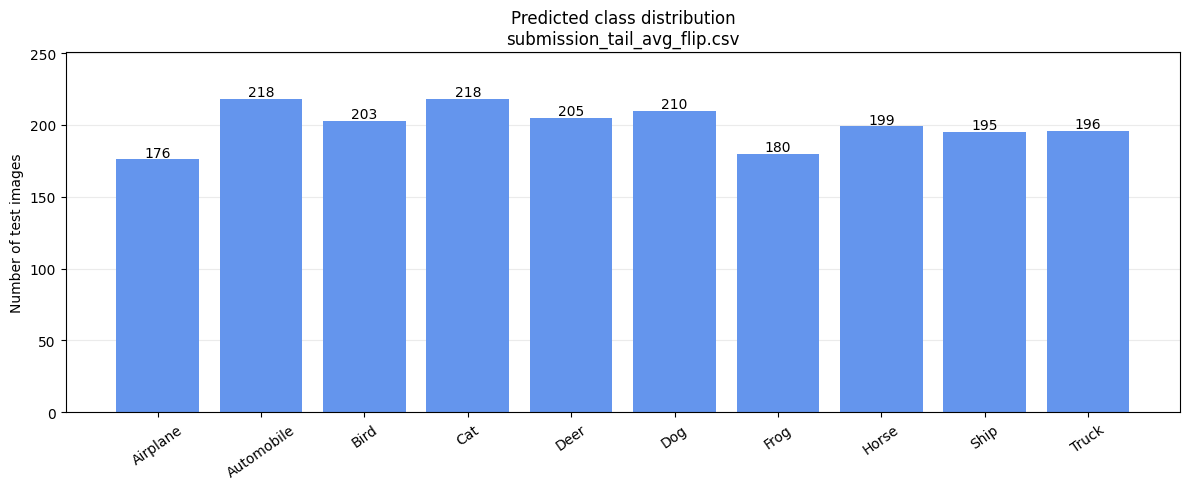


Class-distribution CSV: submission_tail_avg_flip.csv
This shows predicted counts, not per-class accuracy.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [2]:
import json
import io
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files

# Read the student report and submission files.
with zipfile.ZipFile(io.BytesIO(uploaded[student_zip])) as archive:
    members = [
        name for name in archive.namelist()
        if not name.startswith("__MACOSX/")
    ]

    report_name = next(
        name for name in members if name.endswith("/report.json")
    )
    report = json.loads(archive.read(report_name))

    # Each candidate represents one combination of weights and TTA.
    rows = []
    for weights, methods in report["candidates"].items():
        for method, result in methods.items():
            rows.append({
                "Weights": weights,
                "TTA": method,
                "Validation accuracy (%)": result["val_accuracy"],
                "CSV": result["csv"],
            })

    comparison = pd.DataFrame(rows).sort_values(
        "Validation accuracy (%)", ascending=False
    ).reset_index(drop=True)

    # Use the candidate with the highest recorded validation accuracy.
    chosen_csv = comparison.iloc[0]["CSV"]
    submission_name = next(
        name for name in members
        if name.split("/")[-1] == chosen_csv
    )
    predictions = pd.read_csv(
        io.BytesIO(archive.read(submission_name))
    )

display(comparison)


def save_graph(fig, filename):
    fig.tight_layout()
    fig.savefig(OUTPUT / filename, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)


# 1. Compare student weights and test-time augmentation methods.
plot_data = comparison.sort_values("Validation accuracy (%)")
labels = (
    plot_data["Weights"].str.replace("_", " ")
    + " + "
    + plot_data["TTA"]
)
scores = plot_data["Validation accuracy (%)"]

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.barh(labels, scores, color="steelblue")

for bar, score in zip(bars, scores):
    ax.text(
        score + 0.015,
        bar.get_y() + bar.get_height() / 2,
        f"{score:.2f}%",
        va="center",
    )

# A shortened axis makes small differences visible.
ax.set_xlim(max(0, scores.min() - 0.25), min(100, scores.max() + 0.2))
ax.set_xlabel("Validation accuracy (%) — shortened axis")
ax.set_title("Student: weights and TTA comparison")
ax.grid(axis="x", alpha=0.25)
ax.set_axisbelow(True)
save_graph(fig, "student_prediction_methods.png")


# 2. Compare teacher and student EMA validation curves.
fig, ax = plt.subplots(figsize=(10, 5))

for history, name in [
    (teacher_history, "Teacher"),
    (student_history, "Student"),
]:
    ordered = history.sort_values("epoch")
    ax.plot(
        ordered["epoch"], ordered["val_ema"],
        label=name, linewidth=2
    )

ax.set_xlabel("Epoch within each model's training")
ax.set_ylabel("EMA validation accuracy (%)")
ax.set_title("Teacher and student validation accuracy")
ax.legend()
ax.grid(alpha=0.25)
save_graph(fig, "teacher_student_validation.png")


# 3. Compare the recorded student size with the parameter limit.
params = int(report["params"])
limit = 5_000_000

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(
    ["Student", "Parameter limit"],
    [params / 1e6, limit / 1e6],
    color=["seagreen", "lightgray"],
)

for bar, value in zip(bars, [params, limit]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.06,
        f"{value:,}",
        ha="center",
    )

ax.set_ylim(0, 5.6)
ax.set_ylabel("Parameters (millions)")
ax.set_title("Student model size — recorded in report.json")
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)
save_graph(fig, "student_parameter_count.png")

print(f"Recorded student parameters: {params:,}")
print(f"Below the limit by: {limit - params:,} parameters")


# 4. Show predicted test-image counts for each class.
class_names = [
    "Airplane", "Automobile", "Bird", "Cat", "Deer",
    "Dog", "Frog", "Horse", "Ship", "Truck",
]

numeric_labels = pd.to_numeric(predictions["label"], errors="raise")
assert numeric_labels.notna().all(), "Missing predicted labels."
assert (numeric_labels % 1 == 0).all(), "Labels must be integers."
assert numeric_labels.between(0, 9).all(), "Expected labels from 0 to 9."

counts = (
    numeric_labels.astype(int)
    .value_counts()
    .reindex(range(10), fill_value=0)
)

fig, ax = plt.subplots(figsize=(12, 5))
bars = ax.bar(class_names, counts.values, color="cornflowerblue")

for bar, count in zip(bars, counts.values):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        count + 2,
        str(count),
        ha="center",
    )

ax.set_ylim(0, max(counts.values) * 1.15)
ax.set_ylabel("Number of test images")
ax.set_title(f"Predicted class distribution\n{chosen_csv}")
ax.tick_params(axis="x", rotation=35)
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)
save_graph(fig, "predicted_class_distribution.png")

print(f"\nClass-distribution CSV: {chosen_csv}")
print("This shows predicted counts, not per-class accuracy.")


# Download the previous graphs and these new graphs together.
all_graphs_zip = OUTPUT.parent / "all_training_graphs.zip"

with zipfile.ZipFile(
    all_graphs_zip, "w", zipfile.ZIP_DEFLATED
) as archive:
    for image in sorted(OUTPUT.glob("*.png")):
        archive.write(image, arcname=image.name)

files.download(str(all_graphs_zip))